In [1]:
import os, sys, copy, random, subprocess

try:
    import emoji  # noqa: F401
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "emoji"])

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    classification_report, confusion_matrix, f1_score
)
from transformers import AutoTokenizer, AutoModel, SwinModel, get_linear_schedule_with_warmup
from tqdm.auto import tqdm


def seed_everything(seed=42):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

seed_everything(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
use_half = device.type == "cuda"
torch.backends.cudnn.benchmark = True
print("Device:", device)


DATASET_PATH = "/kaggle/input/datasets/charumaurya15/multimodal-fake-news-processed"
CSV_PATH = os.path.join(DATASET_PATH, "master_dataset.csv")
if not os.path.exists(CSV_PATH):
    for root, _, files in os.walk("/kaggle/input"):
        if "master_dataset.csv" in files:
            CSV_PATH = os.path.join(root, "master_dataset.csv")
            DATASET_PATH = root
            break

OUT_DIR = "/kaggle/working" if os.path.isdir("/kaggle/working") else "."
CACHE_PATH = os.path.join(OUT_DIR, "concat_feats_v2.pt")   # v2: new text features
TEXT_COLUMN_CANDIDATES = ["text", "clean_title", "title", "headline", "content"]

NUM_CLASSES = 6
LABEL_NAMES = {0: "True", 1: "Satire / Parody", 2: "Misleading Content",
               3: "Imposter Content", 4: "False Connection", 5: "Manipulated Content"}

MAX_LENGTH = 80
IMG_SIZE = 224
EXTRACT_BS = 128 if torch.cuda.is_available() else 32
AUG_VIEWS = 1                 # raise to 3 for image augmentation (slower extraction)
NUM_WORKERS = min(os.cpu_count() or 2, 8)

# head training
BATCH_SIZE = 128
EPOCHS = 40
LR = 1e-3
WEIGHT_DECAY = 0.01
PATIENCE = 8
PROJ_DIM = 768
DROPOUT = 0.3
LABEL_SMOOTH = 0.05
CLASS_WEIGHTS = True          # sqrt-inverse-frequency weights
N_SEEDS = 3                   # ensemble size

# ------------------------------------------------------------
# Data
# ------------------------------------------------------------
df = pd.read_csv(CSV_PATH)
TEXT_COLUMN = next((c for c in TEXT_COLUMN_CANDIDATES if c in df.columns), None)
if TEXT_COLUMN is None:
    raise ValueError(f"No text column found. Columns: {df.columns.tolist()}")


def get_actual_image_path(row):
    if pd.isna(row["image_path"]):
        return None
    filename = os.path.basename(str(row["image_path"]))
    source = str(row["source"]).lower()
    if source in ("fakenewsnet", "reddit", "twitter"):
        path = os.path.join(DATASET_PATH, source, source, "images", filename)
        return path if os.path.exists(path) else None
    return None


df["actual_image_path"] = df.apply(get_actual_image_path, axis=1)
df = df[df["actual_image_path"].notna() & df[TEXT_COLUMN].notna()].copy()
df[TEXT_COLUMN] = df[TEXT_COLUMN].astype(str)
df = df.reset_index(drop=True)
assert df["label"].between(0, NUM_CLASSES - 1).all()
print("Rows with image + text:", len(df))
print(df["label"].value_counts().sort_index().to_dict())

train_df, temp_df = train_test_split(df, test_size=0.20, random_state=42, stratify=df["label"])
val_df, test_df = train_test_split(temp_df, test_size=0.50, random_state=42, stratify=temp_df["label"])
train_df, val_df, test_df = [d.reset_index(drop=True) for d in (train_df, val_df, test_df)]
print("Split -> train/val/test:", len(train_df), len(val_df), len(test_df))

# ------------------------------------------------------------
# Feature extraction
# ------------------------------------------------------------
MEAN = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1) * 255
STD = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1) * 255

eval_tfms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.PILToTensor(),
])
aug_tfms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.8, 1.0)),
    transforms.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.1, hue=0.03),
    transforms.PILToTensor(),
])


class ImgDS(Dataset):
    def __init__(self, paths, tfm):
        self.paths, self.tfm = paths, tfm

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        img = Image.open(self.paths[i])
        img.draft("RGB", (IMG_SIZE, IMG_SIZE))
        return self.tfm(img.convert("RGB"))


def load_encoders():
    tok = AutoTokenizer.from_pretrained("vinai/bertweet-base", normalization=True)
    te = AutoModel.from_pretrained("vinai/bertweet-base").to(device).eval()
    ie = SwinModel.from_pretrained("microsoft/swin-base-patch4-window7-224",
                                   use_safetensors=True).to(device).eval()
    if use_half:
        te, ie = te.half(), ie.half()
    return tok, te, ie


@torch.inference_mode()
def extract_text(tok, te, texts):
    enc = tok(texts, padding="max_length", truncation=True,
              max_length=MAX_LENGTH, return_tensors="pt")
    ids, mask = enc["input_ids"], enc["attention_mask"]
    out = []
    for i in tqdm(range(0, len(ids), EXTRACT_BS), desc="text", leave=False):
        m = mask[i:i + EXTRACT_BS]
        L = int(m.sum(1).max())
        x = ids[i:i + EXTRACT_BS, :L].to(device)
        m = m[:, :L].to(device)
        o = te(input_ids=x, attention_mask=m, output_hidden_states=True)
        cls = o.last_hidden_state[:, 0].float()                              # [B,768]
        hs = torch.stack(o.hidden_states[-4:]).float().mean(0)               # [B,L,768]
        mf = m.unsqueeze(-1).float()
        mean = (hs * mf).sum(1) / mf.sum(1).clamp(min=1)                     # [B,768]
        out.append(torch.cat([cls, mean], dim=1))                            # [B,1536]
    return torch.cat(out)


@torch.inference_mode()
def extract_image(ie, paths, tfm):
    dl = DataLoader(ImgDS(paths, tfm), batch_size=EXTRACT_BS, shuffle=False,
                    num_workers=NUM_WORKERS, pin_memory=use_half, prefetch_factor=4)
    out = []
    for x in tqdm(dl, desc="image", leave=False):
        x = x.to(device, non_blocking=True).float()
        x = ((x - MEAN) / STD).contiguous(memory_format=torch.channels_last)
        if use_half:
            x = x.half()
        out.append(ie(pixel_values=x).pooler_output.float())
    return torch.cat(out)


def build_split(enc, d, name, views=1):
    tok, te, ie = enc
    print(f"Extracting {name} ({len(d)})...")
    paths = d["actual_image_path"].tolist()
    T = extract_text(tok, te, d[TEXT_COLUMN].tolist())
    V = [extract_image(ie, paths, eval_tfms)]
    for _ in range(views - 1):
        V.append(extract_image(ie, paths, aug_tfms))
    V = torch.stack(V, dim=1)
    y = torch.tensor(d["label"].astype(int).values, device=device)
    return {"T": T, "V": V, "y": y}


sizes = (len(train_df), len(val_df), len(test_df))
feats = None
if os.path.exists(CACHE_PATH):
    c = torch.load(CACHE_PATH, map_location=device)
    if c.get("sizes") == sizes and c.get("views") == AUG_VIEWS:
        feats = c
        print("Loaded cached features:", CACHE_PATH)

if feats is None:
    enc = load_encoders()
    feats = {
        "train": build_split(enc, train_df, "train", AUG_VIEWS),
        "val": build_split(enc, val_df, "val"),
        "test": build_split(enc, test_df, "test"),
        "sizes": sizes, "views": AUG_VIEWS,
    }
    torch.save(feats, CACHE_PATH)
    del enc
    if device.type == "cuda":
        torch.cuda.empty_cache()

# ------------------------------------------------------------
# Standardize features with train statistics
# ------------------------------------------------------------
t_mu, t_sd = feats["train"]["T"].mean(0, keepdim=True), feats["train"]["T"].std(0, keepdim=True) + 1e-6
v_mu = feats["train"]["V"][:, 0].mean(0, keepdim=True)
v_sd = feats["train"]["V"][:, 0].std(0, keepdim=True) + 1e-6
for s in ("train", "val", "test"):
    feats[s]["T"] = (feats[s]["T"] - t_mu) / t_sd
    feats[s]["V"] = (feats[s]["V"] - v_mu.unsqueeze(1)) / v_sd.unsqueeze(1)

T_DIM = feats["train"]["T"].shape[1]
V_DIM = feats["train"]["V"].shape[2]

# ------------------------------------------------------------
# Head: projection heads -> concat -> LayerNorm -> linear softmax
# ------------------------------------------------------------
def make_projection(in_dim, out_dim=PROJ_DIM):
    return nn.Sequential(
        nn.Dropout(0.1), nn.Linear(in_dim, out_dim), nn.GELU(),
        nn.Dropout(DROPOUT), nn.Linear(out_dim, out_dim),
    )


class ConcatHead(nn.Module):
    def __init__(self):
        super().__init__()
        self.text_proj = make_projection(T_DIM)
        self.image_proj = make_projection(V_DIM)
        self.classifier = nn.Sequential(
            nn.LayerNorm(2 * PROJ_DIM), nn.Dropout(DROPOUT),
            nn.Linear(2 * PROJ_DIM, NUM_CLASSES),
        )

    def forward(self, t, v):
        return self.classifier(torch.cat([self.text_proj(t), self.image_proj(v)], dim=1))


# class weights (sqrt inverse frequency, normalized to mean 1)
counts = torch.bincount(feats["train"]["y"], minlength=NUM_CLASSES).float()
cw = (1.0 / counts.sqrt())
cw = (cw / cw.mean()).to(device) if CLASS_WEIGHTS else None
train_crit = nn.CrossEntropyLoss(weight=cw, label_smoothing=LABEL_SMOOTH)


@torch.no_grad()
def get_logits(model, split):
    model.eval()
    f = feats[split]
    return torch.cat([model(f["T"][i:i + 2048], f["V"][i:i + 2048, 0])
                      for i in range(0, len(f["y"]), 2048)])


def metrics_from_probs(probs, y):
    p = probs.argmax(1).cpu().numpy()
    yn = y.cpu().numpy()
    prec, rec, f1, _ = precision_recall_fscore_support(yn, p, average="macro", zero_division=0)
    loss = F.nll_loss(probs.clamp_min(1e-9).log(), y).item()
    return {"loss": loss, "acc": accuracy_score(yn, p), "prec": prec, "rec": rec,
            "f1": f1, "labels": yn, "preds": p}


def train_one(seed):
    seed_everything(seed)
    model = ConcatHead().to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    tr = feats["train"]
    N = len(tr["y"])
    spe = N // BATCH_SIZE
    total = spe * EPOCHS
    sched = get_linear_schedule_with_warmup(opt, int(0.05 * total), total)
    best_f1, best_state, bad = -1.0, None, 0

    for epoch in range(EPOCHS):
        model.train()
        perm = torch.randperm(N, device=device)
        view_idx = torch.randint(0, tr["V"].shape[1], (N,), device=device)
        for s in range(spe):
            idx = perm[s * BATCH_SIZE:(s + 1) * BATCH_SIZE]
            logits = model(tr["T"][idx], tr["V"][idx, view_idx[idx]])
            loss = train_crit(logits, tr["y"][idx])
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
            sched.step()

        pv = F.softmax(get_logits(model, "val"), 1)
        m = metrics_from_probs(pv, feats["val"]["y"])
        print(f"  seed {seed} ep {epoch+1:2d} | val_loss={m['loss']:.4f} "
              f"val_acc={m['acc']:.4f} val_F1={m['f1']:.4f}")
        if m["f1"] > best_f1:
            best_f1, best_state, bad = m["f1"], copy.deepcopy(model.state_dict()), 0
        else:
            bad += 1
            if bad >= PATIENCE:
                break

    model.load_state_dict(best_state)
    print(f"Seed {seed}: best val macro-F1 = {best_f1:.4f}")
    return model


# ------------------------------------------------------------
# Train ensemble, evaluate
# ------------------------------------------------------------
models = [train_one(42 + i) for i in range(N_SEEDS)]


def ens_probs(split):
    return torch.stack([F.softmax(get_logits(m, split), 1) for m in models]).mean(0)


val = metrics_from_probs(ens_probs("val"), feats["val"]["y"])
test = metrics_from_probs(ens_probs("test"), feats["test"]["y"])

print("\n" + "=" * 60)
print(f"CONCAT BASELINE (BERTweet + Swin), {N_SEEDS}-head ensemble")
print("=" * 60)
print(f"VAL  acc={val['acc']:.4f}  macroF1={val['f1']:.4f}")
print(f"TEST Accuracy       : {test['acc']:.4f}")
print(f"TEST Macro Precision: {test['prec']:.4f}")
print(f"TEST Macro Recall   : {test['rec']:.4f}")
print(f"TEST Macro F1       : {test['f1']:.4f}")
print("(Paper reference, Fakeddit official split: Concat macro-F1 = 0.820)")
print("\nClassification report:")
print(classification_report(test["labels"], test["preds"], labels=list(range(NUM_CLASSES)),
                            target_names=[LABEL_NAMES[i] for i in range(NUM_CLASSES)], zero_division=0))
print("Confusion matrix:")
print(confusion_matrix(test["labels"], test["preds"], labels=list(range(NUM_CLASSES))))

Device: cuda
Rows with image + text: 10136
{0: 3971, 1: 1211, 2: 1823, 3: 200, 4: 2508, 5: 423}
Split -> train/val/test: 8108 1014 1014


config.json:   0%|          | 0.00/558 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/843k [00:00<?, ?B/s]

bpe.codes:   0%|          | 0.00/1.08M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.91M [00:00<?, ?B/s]

...

image:   0%|          | 0/8 [00:00<?, ?it/s]

Extracting test (1014)...


text:   0%|          | 0/8 [00:00<?, ?it/s]

image:   0%|          | 0/8 [00:00<?, ?it/s]

  seed 42 ep  1 | val_loss=0.6159 val_acc=0.7821 val_F1=0.7258
  seed 42 ep  2 | val_loss=0.5780 val_acc=0.7909 val_F1=0.7297
  seed 42 ep  3 | val_loss=0.5253 val_acc=0.8225 val_F1=0.7787
  seed 42 ep  4 | val_loss=0.5236 val_acc=0.8333 val_F1=0.7839
  seed 42 ep  5 | val_loss=0.5202 val_acc=0.8363 val_F1=0.7911
  seed 42 ep  6 | val_loss=0.5445 val_acc=0.8333 val_F1=0.7964
  seed 42 ep  7 | val_loss=0.5510 val_acc=0.8452 val_F1=0.7953
  seed 42 ep  8 | val_loss=0.5377 val_acc=0.8314 val_F1=0.7662
  seed 42 ep  9 | val_loss=0.5400 val_acc=0.8432 val_F1=0.7969
  seed 42 ep 10 | val_loss=0.5457 val_acc=0.8353 val_F1=0.7928
  seed 42 ep 11 | val_loss=0.5437 val_acc=0.8343 val_F1=0.7805
  seed 42 ep 12 | val_loss=0.5496 val_acc=0.8491 val_F1=0.7945
  seed 42 ep 13 | val_loss=0.5608 val_acc=0.8442 val_F1=0.7871
  seed 42 ep 14 | val_loss=0.5259 val_acc=0.8412 val_F1=0.7812
  seed 42 ep 15 | val_loss=0.5242 val_acc=0.8442 val_F1=0.7822
  seed 42 ep 16 | val_loss=0.5181 val_acc=0.8383 val_F1

saved: /kaggle/working/1_class_distribution.png


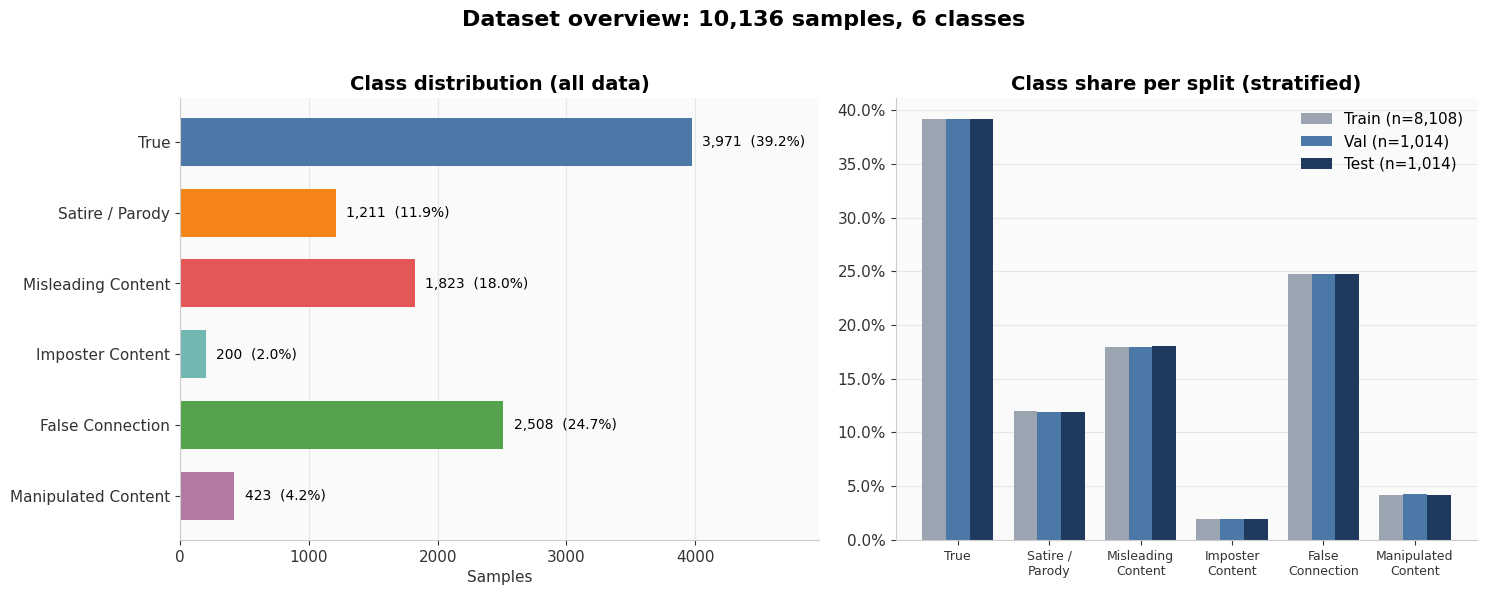

saved: /kaggle/working/2_confusion_matrix.png


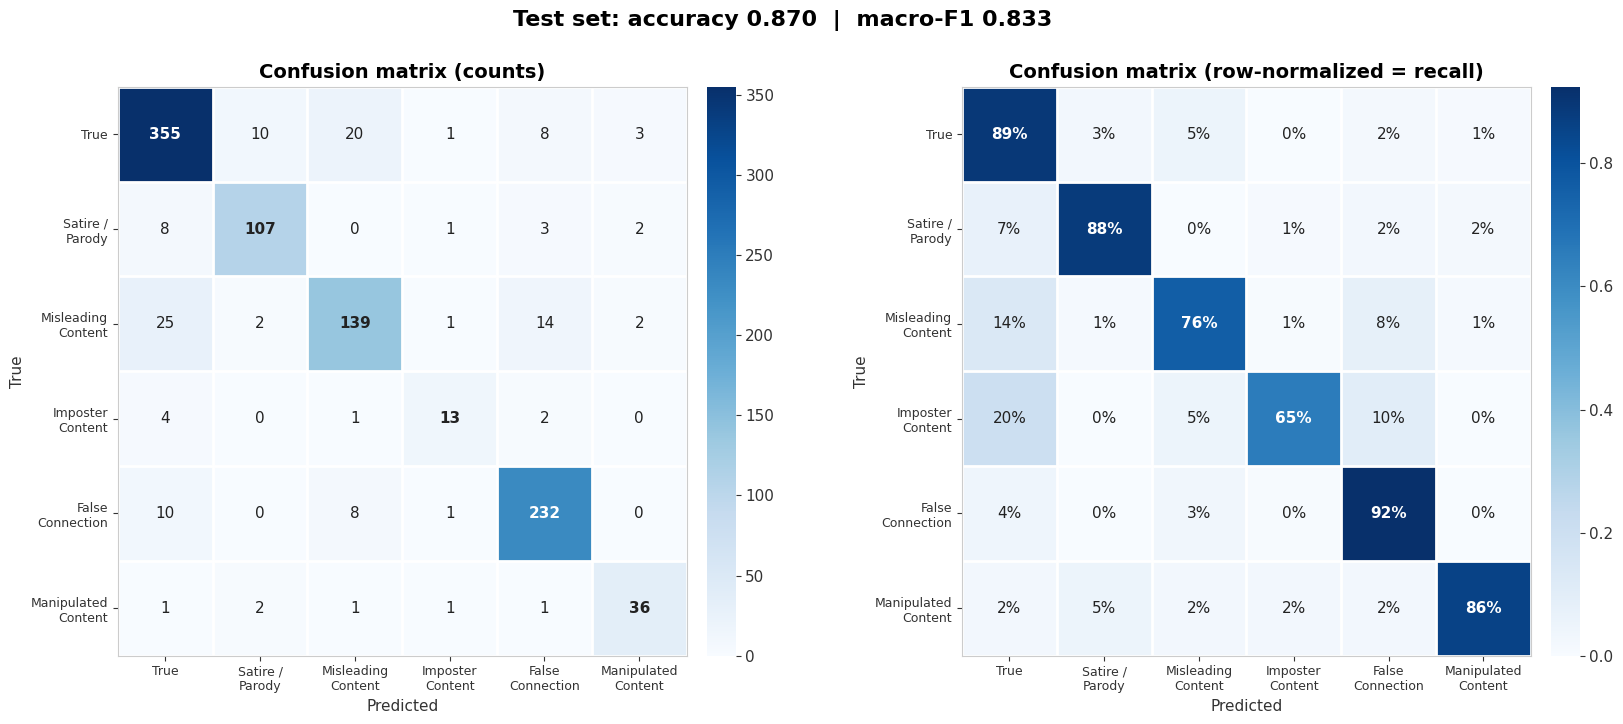

saved: /kaggle/working/3_per_class_metrics.png


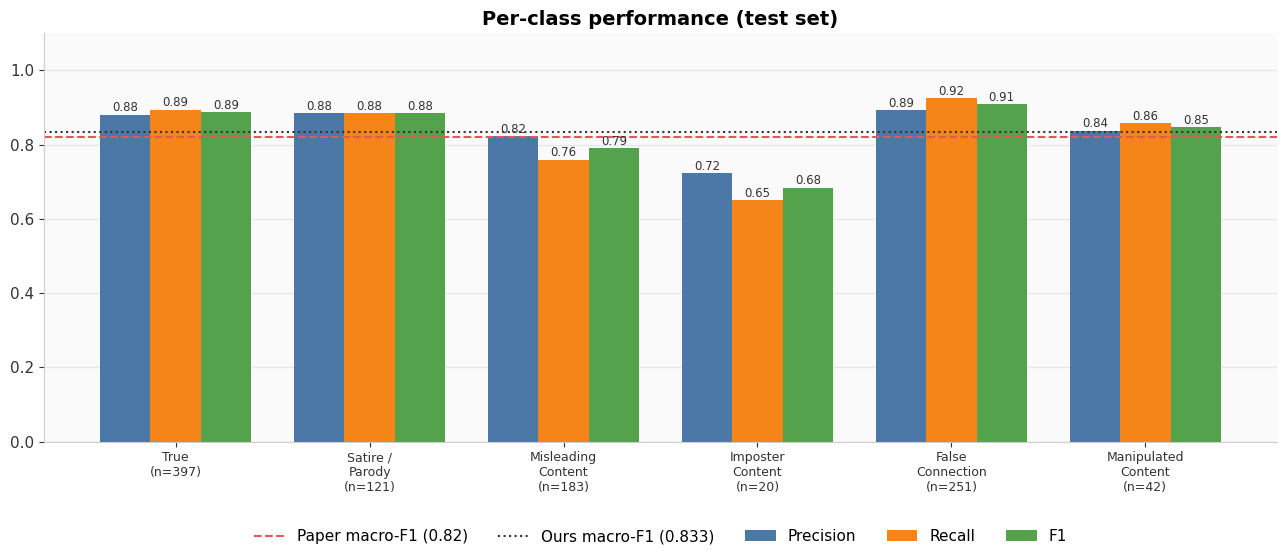

saved: /kaggle/working/4_class_by_source_pie.png


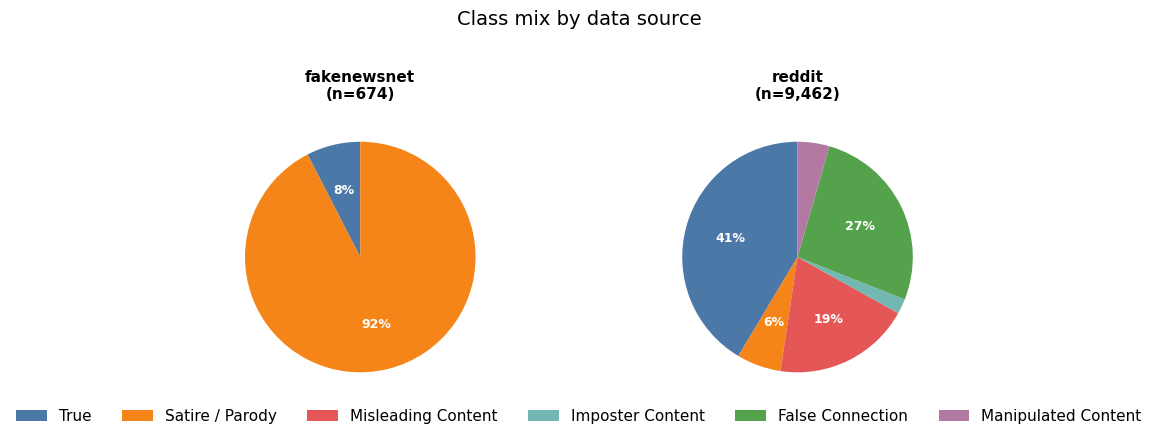

In [4]:
# ============================================================
# GRAPHS
# ============================================================
import os, textwrap
import numpy as np
import math
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support

plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "#FAFAFA",
    "axes.edgecolor": "#CCCCCC", "axes.grid": True, "grid.color": "#E6E6E6",
    "grid.linewidth": 0.8, "axes.axisbelow": True, "font.size": 11,
    "axes.titlesize": 14, "axes.titleweight": "bold", "axes.labelcolor": "#333333",
    "xtick.color": "#333333", "ytick.color": "#333333",
})
PALETTE = ["#4C78A8", "#F58518", "#E45756", "#72B7B2", "#54A24B", "#B279A2"]
SPLIT_COL = ["#9AA5B1", "#4C78A8", "#1F3A5F"]
IDX = list(range(NUM_CLASSES))
NAMES = [LABEL_NAMES[i] for i in IDX]
WRAPPED = [textwrap.fill(n, 11) for n in NAMES]


def clean(ax, grid_axis="y"):
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    ax.grid(axis="x" if grid_axis == "y" else "y", visible=False)


def save(fig, name):
    path = os.path.join(OUT_DIR, name)
    fig.savefig(path, dpi=200, bbox_inches="tight", facecolor="white")
    print("saved:", path)
    plt.show()


# ------------------------------------------------------------
# 1. Class distribution (overall + share per split)
# ------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(15, 5.8), gridspec_kw={"width_ratios": [1.1, 1]})

counts = df["label"].value_counts().reindex(IDX, fill_value=0)
total = counts.sum()
ax = axes[0]
ax.barh(IDX, counts.values, color=PALETTE, height=0.68)
ax.set_yticks(IDX); ax.set_yticklabels(NAMES); ax.invert_yaxis()
for i, v in enumerate(counts.values):
    ax.text(v + total * 0.008, i, f"{v:,}  ({v / total:.1%})", va="center", fontsize=10)
ax.set_xlim(0, counts.max() * 1.25)
ax.set_title("Class distribution (all data)")
ax.set_xlabel("Samples")
clean(ax, "x"); ax.grid(axis="x", visible=True)

ax = axes[1]
w = 0.26
for k, (nm, d) in enumerate([("Train", train_df), ("Val", val_df), ("Test", test_df)]):
    share = d["label"].value_counts(normalize=True).reindex(IDX, fill_value=0).values
    ax.bar(np.arange(NUM_CLASSES) + (k - 1) * w, share, w, label=f"{nm} (n={len(d):,})",
           color=SPLIT_COL[k])
ax.set_xticks(IDX); ax.set_xticklabels(WRAPPED, fontsize=9)
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_title("Class share per split (stratified)")
ax.legend(frameon=False)
clean(ax)
fig.suptitle(f"Dataset overview: {total:,} samples, {NUM_CLASSES} classes", fontsize=16,
             fontweight="bold", y=1.02)
fig.tight_layout()
save(fig, "1_class_distribution.png")

# ------------------------------------------------------------
# 2. Confusion matrix (counts + row-normalized recall)
# ------------------------------------------------------------
cm = confusion_matrix(test["labels"], test["preds"], labels=IDX)
cmn = cm / np.clip(cm.sum(1, keepdims=True), 1, None)

fig, axes = plt.subplots(1, 2, figsize=(17, 7.2))
for ax, M, title, fmt in [(axes[0], cm, "Confusion matrix (counts)", "{:,}"),
                          (axes[1], cmn, "Confusion matrix (row-normalized = recall)", "{:.0%}")]:
    im = ax.imshow(M, cmap="Blues", vmin=0, vmax=M.max())
    ax.set_xticks(IDX); ax.set_yticks(IDX)
    ax.set_xticklabels(WRAPPED, fontsize=9); ax.set_yticklabels(WRAPPED, fontsize=9)
    ax.set_xlabel("Predicted"); ax.set_ylabel("True")
    ax.set_title(title)
    ax.grid(False)
    ax.set_xticks(np.arange(-.5, NUM_CLASSES, 1), minor=True)
    ax.set_yticks(np.arange(-.5, NUM_CLASSES, 1), minor=True)
    ax.grid(which="minor", color="white", linewidth=2)
    ax.tick_params(which="minor", length=0)
    thr = M.max() * 0.55
    for i in IDX:
        for j in IDX:
            ax.text(j, i, fmt.format(M[i, j]), ha="center", va="center",
                    color="white" if M[i, j] > thr else "#222222",
                    fontsize=11, fontweight="bold" if i == j else "normal")
    cb = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03)
    cb.outline.set_visible(False)
acc = (test["labels"] == test["preds"]).mean()
fig.suptitle(f"Test set: accuracy {acc:.3f}  |  macro-F1 {test['f1']:.3f}", fontsize=16,
             fontweight="bold", y=1.0)
fig.tight_layout()
save(fig, "2_confusion_matrix.png")

# ------------------------------------------------------------
# 3. Per-class precision / recall / F1
# ------------------------------------------------------------
p, r, f1, sup = precision_recall_fscore_support(
    test["labels"], test["preds"], labels=IDX, zero_division=0)

fig, ax = plt.subplots(figsize=(13, 5.8))
w = 0.26
for k, (nm, vals, col) in enumerate([("Precision", p, "#4C78A8"),
                                     ("Recall", r, "#F58518"),
                                     ("F1", f1, "#54A24B")]):
    bars = ax.bar(np.arange(NUM_CLASSES) + (k - 1) * w, vals, w, label=nm, color=col)
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.01, f"{v:.2f}", ha="center",
                fontsize=8.5, color="#333333")
ax.axhline(0.82, color="#E45756", ls="--", lw=1.5, label="Paper macro-F1 (0.82)")
ax.axhline(test["f1"], color="#333333", ls=":", lw=1.5, label=f"Ours macro-F1 ({test['f1']:.3f})")
ax.set_xticks(IDX)
ax.set_xticklabels([f"{textwrap.fill(n, 11)}\n(n={s:,})" for n, s in zip(NAMES, sup)], fontsize=9)
ax.set_ylim(0, 1.1)
ax.set_title("Per-class performance (test set)")
ax.legend(frameon=False, ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.18))
clean(ax)
fig.tight_layout()
save(fig, "3_per_class_metrics.png")

# ------------------------------------------------------------
# 4. Class mix by data source
# ------------------------------------------------------------
if "source" in df.columns:
    ct = (
        pd.crosstab(df["source"].astype(str), df["label"])
        .reindex(columns=IDX, fill_value=0)
    )
    pct = ct.div(ct.sum(1), axis=0)
    n_sources = len(ct)
    cols = min(3, n_sources)
    rows = math.ceil(n_sources / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(4.5 * cols, 4 * rows))
    axes = np.atleast_1d(axes).flatten()
    colors = [PALETTE[j] for j in IDX]
    labels = [NAMES[j] for j in IDX]
    for idx, (source, row) in enumerate(pct.iterrows()):
        ax = axes[idx]
        total_n = ct.loc[source].sum()
        wedges, texts, autotexts = ax.pie(row.values,autopct=lambda p: f"{p:.0f}%" if p > 6 else "",colors=colors,startangle=90,textprops={"fontsize": 9, "fontweight": "bold", "color": "white"},
        )
        ax.set_title(f"{source}\n(n={total_n:,})", fontsize=11, pad=10)
    for ax in axes[n_sources:]:
        ax.set_visible(False)
    fig.suptitle("Class mix by data source", fontsize=14, y=1.02)
    fig.legend(
        wedges,labels,loc="lower center",bbox_to_anchor=(0.5, -0.05),ncol=len(IDX),frameon=False,
    )
    fig.tight_layout()
    save(fig, "4_class_by_source_pie.png")